<a href="https://colab.research.google.com/github/aims-ai-research-foundations/airf-multilingual-tokenizer-challenge/blob/main/starter/starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Research Foundations Multilingual Tokenization Challenge

## Can you build the most efficient multilingual tokenizer?

You have six languages, one vocabulary, and a budget of 10,000 tokens.

The full overview, dataset description, rules, scoring formula and submission
steps are in the [competition README](https://github.com/aims-ai-research-foundations/airf-multilingual-tokenizer-challenge).

---

## What This Notebook Provides

This notebook gives you a starting point for the competition:

* Code to load and explore the **training and validation data**.
* A **standard BPE baseline** that defines the reference score.
* A **balanced BPE baseline** showing how one change to the data strategy affects multilingual tokenization.
* The official **validation scoring function**.
* Per-language results for comparing tokenizer performance.
* A **submission checker** for validating your final tokenizer.
* Code to export your tokenizer as `tokenizer.json`.

The baselines are starting points, not solutions.

# Getting Started

Install the pinned competition runtime and download the submission checker.
`tokenizers` must be exactly `0.22.1`, because that is the version official
evaluation uses.

In [1]:
# Colab and Kaggle need the pinned competition runtime installed. A local
# environment created with `uv sync --dev` already has it, and uv virtual
# environments do not ship pip, so this cell installs only what is missing.
from importlib.metadata import PackageNotFoundError, version

TOKENIZERS_VERSION = "0.22.1"


def needs_install(package, exact=None):
    """Return True when a package is absent or not at the required version.

    Args:
        package: Distribution name to look up.
        exact: Version that must match exactly, or None for any version.

    Returns:
        True when pip should install the package.
    """
    try:
        found = version(package)
    except PackageNotFoundError:
        return True
    return exact is not None and found != exact


missing = []
if needs_install("tokenizers", TOKENIZERS_VERSION):
    missing.append(f"tokenizers=={TOKENIZERS_VERSION}")
for package, requirement in (("datasets", "datasets>=4.0,<5"),
                             ("pandas", "pandas"),
                             ("matplotlib", "matplotlib")):
    if needs_install(package):
        missing.append(requirement)

if missing:
    packages = " ".join(missing)
    !pip install -q {packages}
else:
    print("Dependencies already available at the required versions.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 50.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.18.0 requires tokenizers<0.24.0,>=0.23.1, but you have tokenizers 0.22.1 which is incompatible.


In [3]:
# Competition configuration.
GITHUB_REPO = "aims-ai-research-foundations/airf-multilingual-tokenizer-challenge"
GITHUB_BRANCH = "main"
HF_DATASET = "Similoluwa/african-multilingual-tokenizer-challenge"
HF_REVISION = "v1.0.0"

LANGUAGES = ("en", "fr", "ha", "sw", "yo", "am")
LANGUAGE_NAMES = {
    "en": "English",
    "fr": "French",
    "ha": "Hausa",
    "sw": "Swahili",
    "yo": "Yoruba",
    "am": "Amharic",
}
MAX_VOCAB_SIZE = 10_000 # Don't change this. The evaluation script will fail if you do.

# Only these four languages are scored. English and French are guardrails.
SCORED_LANGUAGES = ("ha", "sw", "yo", "am")
GUARDRAIL_RATIO = 1.15
UNKNOWN_PENALTY = 100
RECONSTRUCTION_PENALTY = 3

RAW_URL = f"https://raw.githubusercontent.com/{GITHUB_REPO}/{GITHUB_BRANCH}"

In [4]:
# Make the submission checker importable. A local clone already ships it in
# `starter/`, and Colab or Kaggle downloads it once. This uses urllib rather
# than a shell tool, so it behaves the same on every platform.
import sys
import unicodedata
import urllib.request
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import tokenizers
from datasets import load_dataset
from tokenizers import (Tokenizer, decoders, models, normalizers,
                        pre_tokenizers, trainers)


def local_file(relative_path):
    """Find a repository file when the notebook runs inside a clone.

    Args:
        relative_path: Path relative to the repository root.

    Returns:
        An existing Path, or None when the notebook is not inside a clone.
    """
    for root in (Path.cwd(), *Path.cwd().parents):
        candidate = root / relative_path
        if candidate.is_file():
            return candidate
    return None


def ensure_utils():
    """Put utils.py on the import path, downloading it only when needed.

    Returns:
        The directory added to `sys.path`.
    """
    found = local_file("starter/utils.py") or local_file("utils.py")
    if found is None:
        urllib.request.urlretrieve(f"{RAW_URL}/starter/utils.py", "utils.py")
        found = Path("utils.py").resolve()
    directory = str(found.parent)
    if directory not in sys.path:
        sys.path.insert(0, directory)
    return directory


ensure_utils()
from utils import profile_submission

print("tokenizers version:", tokenizers.__version__)

tokenizers version: 0.22.1


## Load the Dataset

Let's start by loading the competition data and taking a look at what we're working with.

Before building a tokenizer, inspect the size of the dataset, the distribution of languages, and a few examples from each language.

Understanding your data is part of understanding your tokenizer.

In [5]:
def load_competition_data(split):
    """Load one public competition split as a pandas DataFrame.

    Args:
        split: Either "train" or "validation".

    Returns:
        A DataFrame with a `language` column and a `text` column.
    """
    if split not in {"train", "validation"}:
        raise ValueError("only the train and validation splits are public")
    dataset = load_dataset(HF_DATASET, split=split, revision=HF_REVISION)
    frame = dataset.to_pandas()[["language", "text"]]
    return frame.reset_index(drop=True)


train = load_competition_data("train")
validation = load_competition_data("validation")

print(f"Train rows:      {len(train):,}")
print(f"Validation rows: {len(validation):,}")

README.md:   0%|          | 0.00/3.35k [00:00<?, ?B/s]

data/train-am.parquet: reconstructing file:   0%|          |  0.00B / 5.65MB            

data/train-am.parquet: downloading bytes:           |  0.00B            

data/train-en.parquet: reconstructing file:   0%|          |  0.00B / 4.34MB            

data/train-en.parquet: downloading bytes:           |  0.00B            

...

data/validation-yo.parquet: reconstructing file:   0%|          |  0.00B /  457kB            

data/validation-yo.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Train rows:      240,000
Validation rows: 24,000


In [6]:
# Rows are balanced across languages, but characters are not.
summary = train.assign(characters=train.text.str.len()).groupby("language").agg(
    rows=("text", "size"),
    characters=("characters", "sum"),
    mean_length=("characters", "mean"),
)

summary["share_of_characters"] = summary.characters / summary.characters.sum()
summary.index = [LANGUAGE_NAMES[language] for language in summary.index]
summary.sort_values("characters", ascending=False).round(
    {"mean_length": 1, "share_of_characters": 3}
)

,rows,characters,mean_length,share_of_characters
French,40000,5686404,142.2,0.193
English,40000,5429908,135.7,0.184
Hausa,40000,5251977,131.3,0.178
Yoruba,40000,4629899,115.7,0.157
Swahili,40000,4376925,109.4,0.149
Amharic,40000,4079673,102.0,0.139


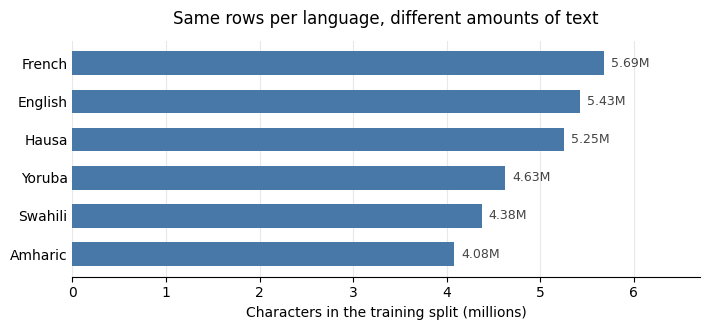

Largest language carries 1.39x the characters of the smallest.


In [7]:
# Every language contributes the same number of rows but not the same amount of
# text, and the tokenizer learns its vocabulary from characters, not from rows.
sizes = summary.characters.sort_values() / 1e6

figure, axes = plt.subplots(figsize=(7.2, 3.4))
bars = axes.barh(sizes.index, sizes.values, height=0.62, color="#4878a8")
axes.bar_label(bars, fmt="%.2fM", padding=5, fontsize=9, color="#444444")

axes.set_xlabel("Characters in the training split (millions)")
axes.set_title("Same rows per language, different amounts of text", pad=12)
axes.set_xlim(0, sizes.max() * 1.18)
axes.xaxis.grid(True, color="#e8e8e8", linewidth=0.8)
axes.set_axisbelow(True)
axes.tick_params(axis="y", length=0)
for edge in ("top", "right", "left"):
    axes.spines[edge].set_visible(False)

plt.tight_layout()
plt.show()

spread = summary.characters.max() / summary.characters.min()
print(f"Largest language carries {spread:.2f}x the characters of the smallest.")

In [8]:
# One random example per language. Re-run this cell to see different text.
for language in LANGUAGES:
    text = train.loc[train.language == language, "text"].sample(1).iloc[0]
    print(f"[{language}] {LANGUAGE_NAMES[language]}")
    print(f"     {text[:120]}")

[en] English
     Version 2.0: The ASF adopted the Apache License 2.0 in January 2004.
[fr] French
     |align=center| tjer||align=center| ṯr ||align=center| X1:D21-M5-A30-Aa29||align=center |estimer, rendre un culte |-
[ha] Hausa
     Dangane da kundin tarihi Britannica (1911), ya kasanche daga farkon wadanda suka fara amfani da ka'idodin humasin don ra
[sw] Swahili
     Wachina ni 22.6%. Wahindi ni 7.3% Lugha rasmi ni Kimalay, lakini zinatumika pia lugha nyingine 136.
[yo] Yoruba
     Didius Julianus (; 30 January 133 tabi 2 February 137 – 1 June 193), je Obaluaye Romu fun osu meta ni odun 193.
[am] Amharic
     ጥያቄ፡-የአብርዬዉ ሸይኽ ሀገራቸዉን ጥለዉ የተሰደዱትበትን‹‹ሁማ ቀዉለሙን ነግ ፊዕለሙን›› የሚለዉ ንግግራቸዉ የአማርኛ ትርጉሙ ምንድን ነዉ---፧ ቦነስ…… ( 5 ነቁጣ) ፧


# Baseline 1: Word Level

## The Efficient Extreme

The simplest way to use few tokens is to give every word its own token.

With a 10,000 token vocabulary you can cover the most frequent words in the
corpus, and each of those becomes exactly one token, so $F_l$ approaches the
theoretical floor of $1.0$.

The problem is everything else. Any word outside the vocabulary becomes
`[UNK]`, and each 1 percent of words that fall back adds 1.00 to the score.
Watch what that does to a tokenizer whose raw fertility is the best possible.

In [9]:
def train_word_level(texts, vocab_size=MAX_VOCAB_SIZE):
    """Give each frequent word a single token, with [UNK] for the rest.

    Args:
        texts: An iterable of training strings.
        vocab_size: The vocabulary budget, at most 10,000.

    Returns:
        A trained `tokenizers.Tokenizer`.
    """
    tokenizer = Tokenizer(models.WordLevel(unk_token="[UNK]"))
    tokenizer.normalizer = normalizers.NFC()
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.WordLevelTrainer(
        vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=True,
    )
    tokenizer.train_from_iterator(texts, trainer=trainer, length=len(texts))
    return tokenizer


word_level = train_word_level(train.text.tolist())
print(f"Learned vocabulary: "
      f"{word_level.get_vocab_size(with_added_tokens=True):,} / {MAX_VOCAB_SIZE:,}")

Learned vocabulary: 10,000 / 10,000


## Score the Baselines

For each language $l$, token fertility is tokens divided by words:

$$F_l = \frac{\text{Number of tokens produced}}{\text{Number of words}}$$

On its own that would reward a tokenizer for refusing to represent hard words,
so unknown tokens carry a heavy penalty:

$$U_l = \frac{\text{Number of [UNK] tokens}}{\text{Number of words}}
\qquad
S_l = F_l + 100\,U_l$$

A 1 percent unknown rate adds $1.00$ to that language's score. Your final score
is the average of $S_l$ across the four target languages:

$$\text{Score} = \frac{S_{\text{ha}} + S_{\text{sw}} + S_{\text{yo}} + S_{\text{am}}}{4}$$

**Lower is better.**

English and French are not scored directly. Each may reach $1.15$ times your
four-language average at no cost, and anything above that is added to your
score:

$$P = \sum_{l \in \{\text{en}, \text{fr}\}} \max\left(0,\ F_l - 1.15\,\bar{F}\right)
\qquad
\text{Score} = \frac{S_{\text{ha}} + S_{\text{sw}} + S_{\text{yo}} + S_{\text{am}}}{4} + P$$

where $\bar{F}$ is your average fertility across the four target languages. Stay
inside the limit and $P$ is exactly zero. Without this the best move is to
abandon English and French, which is not a multilingual tokenizer.

One more term, for the same reason. **Reconstruction** is the share of rows
where `decode(encode(text))` exactly matches the original, and any failure is
charged at three times that share:

$$P_{\text{reconstruction}} = 3 \times (1 - \text{reconstruction})$$

This discourages approaches that artificially reduce token counts by modifying
or deleting information from the input. Unicode NFC, special tokens and a
leading space are all ignored, so a tokenizer that reconstructs every example
receives no penalty.

In [10]:
def count_words(text):
    """Count whitespace-separated words in the original text."""
    return len(text.split())


def measure(tokenizer, data):
    """Compute tokens per word, unknown tokens per word, and reconstruction.

    Args:
        tokenizer: A trained `tokenizers.Tokenizer`.
        data: A DataFrame with `language` and `text` columns.

    Returns:
        A tuple of two dictionaries, fertility and unknown rate, plus the
        share of rows the tokenizer reconstructs exactly.
    """
    tokens = defaultdict(int)
    words = defaultdict(int)
    unknowns = defaultdict(int)
    rebuilt = 0
    unknown_id = tokenizer.token_to_id("[UNK]")
    texts = data.text.tolist()
    encodings = tokenizer.encode_batch(texts, add_special_tokens=False)
    for language, text, encoding in zip(data.language, texts, encodings):
        tokens[language] += len(encoding.ids)
        words[language] += count_words(text)
        if unknown_id is not None:
            unknowns[language] += sum(1 for i in encoding.ids if i == unknown_id)
        # NFC, special tokens and outer whitespace are ignored, because none of
        # them discards any of the original text.
        restored = tokenizer.decode(encoding.ids, skip_special_tokens=True)
        rebuilt += (unicodedata.normalize("NFC", restored).strip()
                    == unicodedata.normalize("NFC", text).strip())
    fertility = {l: tokens[l] / words[l] for l in LANGUAGES}
    unknown_rate = {l: unknowns[l] / words[l] for l in LANGUAGES}
    return fertility, unknown_rate, rebuilt / len(texts)


def score(tokenizer, data=validation, name="candidate"):
    """Score a tokenizer with the official competition metric.

    Returns:
        A dictionary with the score, per language detail, and the guardrail and
        reconstruction penalties that are included in that score.
    """
    fertility, unknown_rate, reconstruction = measure(tokenizer, data)
    penalised = {l: fertility[l] + UNKNOWN_PENALTY * unknown_rate[l] for l in LANGUAGES}
    value = sum(penalised[l] for l in SCORED_LANGUAGES) / len(SCORED_LANGUAGES)
    budget = (sum(fertility[l] for l in SCORED_LANGUAGES)
              / len(SCORED_LANGUAGES)) * GUARDRAIL_RATIO
    overages = {l: max(0.0, fertility[l] - budget) for l in ("en", "fr")}
    penalty = sum(overages.values())
    reconstruction_penalty = RECONSTRUCTION_PENALTY * (1 - reconstruction)
    return {
        "name": name,
        "score": value + penalty + reconstruction_penalty,
        "fertility": fertility,
        "unknown_rate": unknown_rate,
        "penalised": penalised,
        "budget": budget,
        "penalty": penalty,
        "overages": overages,
        "reconstruction": reconstruction,
        "reconstruction_penalty": reconstruction_penalty,
        "vocab_size": tokenizer.get_vocab_size(with_added_tokens=True),
    }


def show_score(result):
    """Print one scored result as a per language table."""
    print(f"{result['name']}: SCORE {result['score']:.4f}   "
          f"vocabulary {result['vocab_size']:,}")
    print(f"  {'language':<10}{'tokens/word':>13}{'[UNK] rate':>12}{'score':>9}")
    for language in LANGUAGES:
        marker = "*" if language in SCORED_LANGUAGES else " "
        print(f"  {LANGUAGE_NAMES[language] + marker:<10}"
              f"{result['fertility'][language]:>13.3f}"
              f"{result['unknown_rate'][language]:>12.4f}"
              f"{result['penalised'][language]:>9.3f}")
    print(f"  guardrail {result['budget']:.3f}, penalty {result['penalty']:.4f}")
    for language, overage in result["overages"].items():
        if overage > 0:
            print(f"  {LANGUAGE_NAMES[language]} is {overage:.3f} over, "
                  f"adding {overage:.3f} to the score")
    print(f"  reconstruction {result['reconstruction'] * 100:.1f}%, "
          f"penalty {result['reconstruction_penalty']:.4f}")


word_result = score(word_level, name="Baseline 1: Word level")
show_score(word_result)

Baseline 1: Word level: SCORE 36.9859   vocabulary 10,000
  language    tokens/word  [UNK] rate    score
  English           1.183      0.2724   28.427
  French            1.250      0.2920   30.446
  Hausa*            1.186      0.2198   23.170
  Swahili*          1.177      0.2867   29.844
  Yoruba*           1.212      0.2849   29.702
  Amharic*          1.247      0.5203   53.276
  guardrail 1.386, penalty 0.0000
  reconstruction 0.4%, penalty 2.9878


# Baseline 2: Character Level

## The Complete Extreme

Now go the other way. Give every character its own token, and fall back to raw
bytes for anything unseen.

This tokenizer can represent absolutely everything, so its `[UNK]` rate is
zero and it pays no penalty at all. It is also enormously wasteful: a word of
eight characters costs eight tokens.

**Same vocabulary budget. Opposite trade-off.**

In [11]:
def train_character_level(texts, min_count=20):
    """Give each common character a single token, with byte fallback.

    Byte fallback is what satisfies the coverage requirement: a character
    missing from the vocabulary is still representable as raw bytes.

    Args:
        texts: An iterable of training strings.
        min_count: How often a character must appear to earn its own token.

    Returns:
        A `tokenizers.Tokenizer` that represents any input.
    """
    counts = Counter(character for text in texts for character in text)
    alphabet = [character for character, seen in counts.most_common()
                if seen >= min_count]

    vocab = {"[UNK]": 0}
    for character in alphabet:
        vocab.setdefault(character, len(vocab))
    for value in range(256):
        vocab.setdefault(f"<0x{value:02X}>", len(vocab))

    model = models.BPE(vocab=vocab, merges=[], unk_token="[UNK]",
                       byte_fallback=True)
    tokenizer = Tokenizer(model)
    tokenizer.normalizer = normalizers.NFC()
    tokenizer.decoder = decoders.ByteFallback()
    return tokenizer


character_level = train_character_level(train.text.tolist())
size = character_level.get_vocab_size(with_added_tokens=True)
print(f"Vocabulary: {size:,} / {MAX_VOCAB_SIZE:,}")

character_result = score(character_level, name="Baseline 2: Character level")
show_score(character_result)

Vocabulary: 1,008 / 10,000
Baseline 2: Character level: SCORE 5.6815   vocabulary 1,008
  language    tokens/word  [UNK] rate    score
  English           6.163      0.0000    6.163
  French            6.266      0.0000    6.266
  Hausa*            5.788      0.0000    5.788
  Swahili*          6.362      0.0000    6.362
  Yoruba*           5.474      0.0000    5.474
  Amharic*          5.101      0.0000    5.101
  guardrail 6.534, penalty 0.0000
  reconstruction 100.0%, penalty 0.0000


## Compare the Baselines

The two baselines bracket the problem.

| Tokenizer | Tokens per word | `[UNK]` rate | Score |
| --- | ---: | ---: | ---: |
| Word level | lowest possible | high | terrible |
| Character level | high | zero | mediocre |

Neither is a good tokenizer. One wins on fertility and loses everything to the
penalty, the other pays no penalty but spends far too many tokens.

**Your job is to find something in between.** A good subword tokenizer keeps
full coverage while spending far fewer tokens per word than character level.

In [12]:
# Both baselines side by side, with the per language detail.
comparison = pd.DataFrame(
    [
        {"tokenizer": result["name"],
         "score": round(result["score"], 4),
         "fertility": round(
             sum(result["fertility"][l] for l in SCORED_LANGUAGES) / 4, 3),
         "unk rate": round(
             sum(result["unknown_rate"][l] for l in SCORED_LANGUAGES) / 4, 4),
         "vocabulary": result["vocab_size"],
         **{language: round(result["penalised"][language], 3)
            for language in LANGUAGES}}
        for result in (word_result, character_result)
    ]
).set_index("tokenizer")

comparison

,score,fertility,unk rate,vocabulary,en,fr,ha,sw,yo,am
tokenizer,,,,,,,,,,
Baseline 1: Word level,36.9859,1.206,0.3279,10000,28.427,30.446,23.170,29.844,29.702,53.276
Baseline 2: Character level,5.6815,5.682,0.0000,1008,6.163,6.266,5.788,6.362,5.474,5.101


In [13]:
def train_champion_bpe(df, vocab_size=MAX_VOCAB_SIZE):
    """Train the optimized BPE tokenizer with weighted language sampling.

    Args:
        df: The training dataframe containing 'language' and 'text' columns.
        vocab_size: Maximum vocabulary size allowed.

    Returns:
        A trained `tokenizers.Tokenizer` instance.
    """
    balanced_texts = []
    for _, row in df.iterrows():
        lang = row["language"]
        text = row["text"]

        if lang == "am":
            balanced_texts.extend([text] * 4)
        elif lang == "yo":
            balanced_texts.extend([text] * 3)
        elif lang in ("sw", "ha"):
            balanced_texts.extend([text] * 2)
        else:
            balanced_texts.append(text)

    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]", byte_fallback=True))
    tokenizer.normalizer = normalizers.NFC()
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=["[UNK]"],
        show_progress=True
    )

    tokenizer.train_from_iterator(balanced_texts, trainer=trainer, length=len(balanced_texts))
    return tokenizer


champion_tokenizer = train_champion_bpe(train)
size = champion_tokenizer.get_vocab_size(with_added_tokens=True)
print(f"Vocabulary: {size:,} / {MAX_VOCAB_SIZE:,}")

champion_result = score(champion_tokenizer, name="Champion BPE (AM:4, YO:3, SW/HA:2)")
show_score(champion_result)

Vocabulary: 10,000 / 10,000
Champion BPE (AM:4, YO:3, SW/HA:2): SCORE 2.0347   vocabulary 10,000
  language    tokens/word  [UNK] rate    score
  English           2.044      0.0000    2.044
  French            2.210      0.0000    2.210
  Hausa*            1.771      0.0000    1.771
  Swahili*          1.973      0.0000    1.973
  Yoruba*           2.054      0.0000    2.054
  Amharic*          2.341      0.0000    2.341
  guardrail 2.340, penalty 0.0000
  reconstruction 100.0%, penalty 0.0000


# Your Turn

## Can You Beat the Baselines?

You have seen the two extremes. One is efficient but cannot represent unseen
words. The other represents everything but spends far too many tokens.

A subword tokenizer sits between them, and that is where the competition is.

Here are some directions you could explore:

* **Tokenizer algorithm:** BPE, WordPiece and Unigram build vocabularies on
  completely different principles, and they behave differently on Amharic.
* **Pre-tokenization:** how should text be split before vocabulary learning
  begins? This is one of the largest levers available.
* **Language balance:** you have 10,000 slots for six languages but only four
  of them are scored. How should the budget be shared? Remember the guardrail.
* **Normalization:** how should Unicode, casing, punctuation and different
  scripts be handled?
* **Vocabulary design:** how can you make better use of the budget?
* **Combinations:** can several individually useful ideas work together?

**Pick an idea → make one change → measure the result → keep what works.**

# Prepare Your Submission

Found something that beats the baselines?

Export your final tokenizer as `tokenizer.json`, then run the official submission checker.

The checker verifies that your tokenizer:

* Loads correctly with the pinned `tokenizers` version.
* Has no more than **10,000 tokens**.
* Can tokenize text from all six languages.
* Reports the English and French guardrail penalty added to your score.
* Reports your **reconstruction penalty**, charged on any example your
  tokenizer fails to rebuild exactly.
* Meets the required submission format.

It also reports your fertility, your `[UNK]` rate and your final score for each
language, so you can see exactly where the score is coming from before you
submit.

In [14]:
# Sélection du meilleur tokenizer (Champion BPE)
best = champion_tokenizer
best_result = champion_result

# Sauvegarde du tokenizer au format requis pour la soumission
best.save("tokenizer.json", pretty=True)
print(f"Tokenizer sauvegardé : {best_result['name']} avec un score de {best_result['score']:.4f}\n")

# Validation officielle de la soumission
report = profile_submission("tokenizer.json", data=validation)

Tokenizer sauvegardé : Champion BPE (AM:4, YO:3, SW/HA:2) avec un score de 2.0347

AI Research Foundations Multilingual Tokenization Challenge
Submission checker

Loading tokenizer......... ✓
File size................. ✓
Vocabulary................ ✓ 10,000 / 10,000
Encoding.................. ✓
Compatibility............. ✓

Scores (24,000 rows, lower is better)
language      tokens/word  [UNK] rate    score
English             2.044      0.0000    2.044
French              2.210      0.0000    2.210
Hausa*              1.771      0.0000    1.771
Swahili*            1.973      0.0000    1.973
Yoruba*             2.054      0.0000    2.054
Amharic*            2.341      0.0000    2.341
Guardrail penalty......... 0.0000
Reconstruction penalty.... 0.0000
SCORE..................... 2.0347
  * scored languages
  guardrail 2.340, highest is French at 2.210 (5.6% headroom)
  reconstruction 100.0%, charged 3 x the share not reconstructed

Local benchmark (informational only)
Evaluation time.....

In [20]:
import yaml

# Team metadata information
team_info = {
    "team_name": "bertrand noubissi ",
    "members": [
        {
            "name": "Bertrand Noubissi Kouontchou",
            "email": "bertrandnoubissi12@gmail.com"
        }
    ]
}

# Save the dictionary to metadata.yml formatted as YAML
with open("metadata.yml", "w", encoding="utf-8") as f:
    yaml.dump(team_info, f, default_flow_style=False)

print("Success: metadata.yml has been saved successfully!")

Success: metadata.yml has been saved successfully!


## Final Checklist

Before submitting, make sure:

* Your tokenizer has been evaluated on the validation set.
* You have checked its performance across all six languages.
* Your vocabulary contains no more than **10,000 tokens**.
* Your final file is named `tokenizer.json`.
* Your tokenizer passes the submission checker.

Your local validation score is for experimentation.

Your position on the leaderboard is determined using the **hidden test set**.

**Submit your tokenizer, see where you rank, and keep improving.**

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# References

This challenge builds on concepts introduced in the **AI Research Foundations** learning path:

* **Course 01: Build Your Own Small Language Model** introduces the language model pipeline and where tokenization fits into building a language model.
* **Course 02: Represent Your Language Data** explores how text is represented for language models, including tokenization and vocabulary construction.

**AI Research Foundations Learning Path:**
https://www.skills.google/paths/3135